# FFSM++ Oracle paper output parser #

### Header ###

In [1]:
import sys          # only needed to determine Python version number
import pandas as pd
import numpy as np
from pandas import DataFrame, Series
import output_parser_lib as parserlib

# Matplotlib options
import matplotlib.pyplot as plt
import matplotlib   # only needed to determine Matplotlib version number
# Render plots inline:
%matplotlib inline  
pd.set_option('display.mpl_style', 'default') # Make the graphs a bit prettier
plt.rcParams['figure.figsize'] = (15, 5)

pd.set_option('display.max_rows', 88)


### Global variables ###

In [2]:
scenarios = ["RCP00_BAS_EXT",            "RCP00_BAS_ADAPT_BASE",        "RCP00_BAS_ADAPT_REFORESTATION_ACTIVEMGM",
             "RCP00_BAS_ADAPT_SUBSIDES", "RCP00_BAS_ADAPT_OPENMARKETS", "RCP00_BAS_ADAPT_STUCTURALPOLICIES",
             "RCP00_BAS_ADAPT"]
scenarios_adapt = [ "RCP00_BAS_ADAPT_BASE", "RCP00_BAS_ADAPT_REFORESTATION_ACTIVEMGM",
             "RCP00_BAS_ADAPT_SUBSIDES", "RCP00_BAS_ADAPT_OPENMARKETS", "RCP00_BAS_ADAPT_STUCTURALPOLICIES",
             "RCP00_BAS_ADAPT"]
#scenarios = ['constant']

baseIDir = 'results'



products_map = {'hardWRoundW': 'Hardwood Roundwood', 'softWRoundW': 'Softwood Roundwood',
                'pulpWFuelW': 'Pulpwood and Fuelwood', 'fuelW': 'Fuelwood', 'hardWSawnW': 'Hardwood Sawnwood',
                'softWSawnW': 'Softwood Sawnwood', 'plyW': 'Plywood', 'pulpW': 'Pulpwood', 'pannels': 'Pannels'}

# sigma – prix elasticity (supply and demand)
sigma_map = {'hardWRoundW': 1.2, 'softWRoundW': 0.9, 'pulpWFuelW': 0.9, 'fuelW': -0.6, 'hardWSawnW': -0.5,
             'softWSawnW': -0.4, 'plyW': -0.3, 'pannels': -0.5, 'pulpW': -0.5}

fgroup_map = {
 "Fut_Feu":  "Broadleaved",
 "Fut_Mix":  "Mixed",
 "Fut_Con":  "Coniferous",
 "Mel_Feu":  "Broadleaved",
 "Mel_Mix":  "Mixed",
 "Tail_Feu": "Broadleaved",
 np.nan:     "All forests",
 "broadL":   "Broadleaved",
 "mixedBC":  "Mixed",
 "con":      "Coniferous",
}


fgroup_map2 = {'con': 'Coniferous', 'broadL': 'Broadleaved'}

regions_map_oldid_to_short = {11001: 'AlsChaLor',
  11002: 'AquPoi',
  11003: 'AuvLim',
  11004: 'BasHau',
  11005: 'BouFra',
  11006: 'BrePay',
  11007: 'Cen',
  11008: 'Cor',
  11009: 'IleNorPic',
  11010: 'LanPro',
  11011: 'Mid',
  11012: 'Rho',
  11000: 'France'
}

gamma = 0.5
trs   = 0.5

### Definition of helper functions ##

In [3]:
def form_i(x):
    return "{:0,.0f}".format(x)  # e.g. 1234567.890 --> 1,234,567
def form_f2(x):
    return "{:0,.2f}".format(x)  # e.g. 1234567.890 --> 1,234,567.89
def form_f3(x):
    return "{:0,.3f}".format(x)  # e.g. 1234567.890 --> 1,234,567.890

def JoinMulti(DFList):
    FinalDF=DFList[0].reset_index()
    for OtherDF in DFList[1:]:
        FinalDF=pd.merge(FinalDF, OtherDF.reset_index(), how='outer')
    #Now I want reindex it so that it's indexed the same as the `DataFrame` with the highest number of levels
    NLevels=[x.index.nlevels for x in DFList]
    MaxIndexPos=NLevels.index(max(NLevels))
    FinalIndex=DFList[MaxIndexPos].index
    FinalDF=FinalDF.set_index(FinalIndex.names).reindex(FinalIndex)
    return FinalDF

### Data import ###
(may take long time)

In [4]:
forestData_byscenario = [pd.read_csv(baseIDir+'/forestData_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
forestDataReg = pd.concat(forestData_byscenario)
forestDataReg = forestDataReg.drop(['Unnamed: 8'],axis=1) # we don't want this column never
forestDataReg = forestDataReg.drop(['country'],axis=1) # we don't want this column never
productData_byscenario = [pd.read_csv(baseIDir+'/productData_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
productDataReg = pd.concat(productData_byscenario)
productDataReg = productDataReg.drop(['Unnamed: 8'],axis=1) # we don't want this column never
productDataReg = productDataReg.drop(['country'],axis=1) # we don't want this column never
carbonData_byscenario = [pd.read_csv(baseIDir+'/carbonBalance_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
carbonDataReg = pd.concat(carbonData_byscenario)
carbonDataReg = carbonDataReg.drop(['Unnamed: 6'],axis=1) # we don't want this column never
carbonDataReg = carbonDataReg.drop(['country'],axis=1) # we don't want this column never

### Common data tidying ###

In [5]:
forestDataReg['spGroup'] = forestDataReg['forType']
forestDataReg.replace({'spGroup': fgroup_map}, inplace=True) # doesn't work on index, only on a column
productDataReg['prodLev'] = np.where(productDataReg['prod'].isin(['hardWRoundW', 'softWRoundW', 'pulpWFuelW','ashRoundW']), 'priProd', 'secProd')
productDataReg.replace({'freeDim': regions_map_oldid_to_short}, inplace=True)

### Ecological - ecosystem services dimension ###

#### Area of total forest by region:  table now and 2100 (just to report regions with maximum variations) ####
Unit: ha

In [12]:
# creating tables forArea_total_arpege_a1b and forArea_total_a1b
forArea = forestDataReg[forestDataReg['parName'] == 'forArea'].copy()
#forArea.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column
#forArea.replace({'region': regions_map_name_to_short}, inplace=True)
#forArea.replace({'region': regions_map_id_to_short}, inplace=True)
forArea = forArea.drop(['freeDim','parName','forType'],axis=1) # we don't want these columns never
forArea_byGroup = forArea.groupby(['scen','region','year','spGroup'], as_index=False).agg(np.sum)
forArea_total = forArea.groupby(['scen','region','year'], as_index=False).agg(np.sum)
forArea_total = forArea_total[forArea_total['year'].isin([2015,2050,2100])]
"""
forArea_total_arpege_a1b = forArea_total[forArea_total['scen'] == 'arpege_a1b']
forArea_total_arpege_a1b = forArea_total_arpege_a1b.drop(['scen'], axis=1)
forArea_total_arpege_a1b.set_index(['region','year'], inplace=True)
forArea_total_arpege_a1b = forArea_total_arpege_a1b.unstack(['year'])
forArea_total_arpege_a1b.columns = forArea_total_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL

forArea_total_arpege_a1b['diff'] = forArea_total_arpege_a1b[2100]-forArea_total_arpege_a1b[2015]
forArea_total_arpege_a1b.loc['France'] = forArea_total_arpege_a1b.sum()

forArea_total_a1b = forArea_total[forArea_total['scen'].isin(scenarios_a1b)]
forArea_total_a1b_2100 = forArea_total_a1b[forArea_total_a1b['year']==2100]
forArea_total_a1b_2100 = forArea_total_a1b_2100.groupby(['scen']).agg(np.sum)
#print(forArea_total_a1b_2100)

forArea_total_a1b = forArea_total_a1b.groupby(['region','year']).agg(np.mean)
forArea_total_a1b = forArea_total_a1b.unstack(['year'])
forArea_total_a1b.columns = forArea_total_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL

forArea_total_a1b['diff'] = forArea_total_a1b[2100]-forArea_total_a1b[2015]

forArea_total_a1b.loc['France'] = forArea_total_a1b.sum()
forArea_total_a1b_Mha = forArea_total_a1b/1000000
forArea_total_a1b_Mha['diff_pc'] = 100*forArea_total_a1b_Mha['diff']/forArea_total_a1b_Mha[2015]
print("Notes:")
print("These results are direct results of the work of Anne. We can ask her how much confident is she on these before deciding which exposition give to them (Appendix, main text..)")

forArea_total_a1b_Mha
"""
#print (forArea_total_a1b.to_latex(formatters=[form1, form1, form1]))


'\nforArea_total_arpege_a1b = forArea_total[forArea_total[\'scen\'] == \'arpege_a1b\']\nforArea_total_arpege_a1b = forArea_total_arpege_a1b.drop([\'scen\'], axis=1)\nforArea_total_arpege_a1b.set_index([\'region\',\'year\'], inplace=True)\nforArea_total_arpege_a1b = forArea_total_arpege_a1b.unstack([\'year\'])\nforArea_total_arpege_a1b.columns = forArea_total_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL\n\nforArea_total_arpege_a1b[\'diff\'] = forArea_total_arpege_a1b[2100]-forArea_total_arpege_a1b[2015]\nforArea_total_arpege_a1b.loc[\'France\'] = forArea_total_arpege_a1b.sum()\n\nforArea_total_a1b = forArea_total[forArea_total[\'scen\'].isin(scenarios_a1b)]\nforArea_total_a1b_2100 = forArea_total_a1b[forArea_total_a1b[\'year\']==2100]\nforArea_total_a1b_2100 = forArea_total_a1b_2100.groupby([\'scen\']).agg(np.sum)\n#print(forArea_total_a1b_2100)\n\nforArea_total_a1b = forArea_total_a1b.groupby([\'region\',\'year\']).agg(np.mean)\nforArea_total_a1b = forArea_total_a1b.unstack([

#### Share of broadleaved/coniferous:  table now/2100 by region ####

In [14]:
forArea_byGroup_a1b = forArea_byGroup[forArea_byGroup['scen'] == "RCP00_BAS_ADAPT"]
forArea_byGroup_a1b = forArea_byGroup_a1b[forArea_byGroup_a1b['year'].isin([2012,2050])]
forArea_byGroup_a1b = forArea_byGroup_a1b.groupby(['region','year','spGroup']).agg(np.mean)
forArea_byGroup_a1b = forArea_byGroup_a1b.unstack(['year','spGroup'])
forArea_byGroup_a1b.columns = forArea_byGroup_a1b.columns.droplevel()
forArea_byGroup_a1b

year             2012                              2050                      
spGroup   Broadleaved Coniferous      Mixed Broadleaved Coniferous      Mixed
region                                                                       
AlsChaLor  1298208.56   309366.0  184499.60  1184113.48   376342.0  231618.40
AquPoi      877711.00   734529.0  279545.30   721453.70   929432.0  240898.40
AuvLim      637786.20   415714.0  245378.40   540128.90   433818.0  324930.00
BasHau      294904.10    42261.9   23971.15   239444.64    95059.5   26633.53
BouFra     1279640.20   242929.0  124350.10  1149970.40   337558.0  159390.60
BrePay      323584.80   142124.0   79820.20   265871.90   211878.0   67779.10
Cen         698253.50   102464.0   55893.50   581269.30   227057.0   48284.40
Cor         190705.30    44532.3   21372.40   176043.90    47030.0   33536.20
IleNorPic   622144.90    29325.8   23528.18   557428.30    69049.3   48520.70
LanPro      850235.00   708622.0  423796.00   847653.00   680792.0  454207.00
Mid         966514.60   126456.0   97399.20   864933.10   168789.0  156646.90
Rho         704487.20   539712.0  366409.40   682291.00   539764.0  388554.60

In [13]:
#forArea_byGroup_arpege_a1b = forArea_byGroup[forArea_byGroup['scen'] == 'arpege_a1b']
#forArea_byGroup_arpege_a1b = forArea_byGroup_arpege_a1b.drop(['scen'], axis=1)
#forArea_byGroup_arpege_a1b = forArea_byGroup_arpege_a1b[forArea_byGroup_arpege_a1b['year'].isin([2015,2100])]
#forArea_byGroup_arpege_a1b.set_index(['region','year','spGroup'], inplace=True)
#forArea_byGroup_arpege_a1b=forArea_byGroup_arpege_a1b.unstack(['year','spGroup'])
#forArea_byGroup_arpege_a1b.columns = forArea_byGroup_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
#forArea_byGroup_arpege_a1b.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)
#forArea_byGroup_arpege_a1b.loc['France'] = forArea_byGroup_arpege_a1b.sum()
#forArea_byGroup_arpege_a1b[2015,'Broadleaved'] = 100 * forArea_byGroup_arpege_a1b[2015,'br'] / (forArea_byGroup_arpege_a1b[2015,'br']+forArea_byGroup_arpege_a1b[2015,'con']) 
#forArea_byGroup_arpege_a1b[2015,'Coniferous'] = 100 * forArea_byGroup_arpege_a1b[2015,'con'] / (forArea_byGroup_arpege_a1b[2015,'br']+forArea_byGroup_arpege_a1b[2015,'con']) 
#forArea_byGroup_arpege_a1b[2100,'Broadleaved'] = 100 * forArea_byGroup_arpege_a1b[2100,'br'] / (forArea_byGroup_arpege_a1b[2100,'br']+forArea_byGroup_arpege_a1b[2100,'con']) 
#forArea_byGroup_arpege_a1b[2100,'Coniferous'] = 100 * forArea_byGroup_arpege_a1b[2100,'con'] / (forArea_byGroup_arpege_a1b[2100,'br']+forArea_byGroup_arpege_a1b[2100,'con']) 
#forArea_byGroup_arpege_a1b.drop([(2015,'br'),(2015,'con'),(2100,'br'),(2100,'con')], axis=1, inplace=True)
#forArea_byGroup_arpege_a1b
#print (forArea_byGroup_arpege_a1b.to_latex(formatters=[form2, form2, form2, form2]))

forArea_byGroup_a1b = forArea_byGroup[forArea_byGroup['scen'] == "RCP00_BAS_ADAPT"]
forArea_byGroup_a1b = forArea_byGroup_a1b[forArea_byGroup_a1b['year'].isin([2012,2050])]
forArea_byGroup_a1b = forArea_byGroup_a1b.groupby(['region','year','spGroup']).agg(np.mean)
forArea_byGroup_a1b = forArea_byGroup_a1b.unstack(['year','spGroup'])
forArea_byGroup_a1b.columns = forArea_byGroup_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forArea_byGroup_a1b.columns.set_levels([ [2012, 2050], ['br', 'con','mix']], inplace=True)
forArea_byGroup_a1b.loc['France'] = forArea_byGroup_a1b.sum()
forAreaShare_byGroup_a1b = forArea_byGroup_a1b.copy()
forAreaShare_byGroup_a1b[2012,'Broadleaved'] = 100 * forArea_byGroup_a1b[2012,'br']  / (forArea_byGroup_a1b[2012,'br']+forArea_byGroup_a1b[2012,'con']) 
forAreaShare_byGroup_a1b[2012,'Coniferous']  = 100 * forArea_byGroup_a1b[2012,'con'] / (forArea_byGroup_a1b[2012,'br']+forArea_byGroup_a1b[2012,'con']) 
forAreaShare_byGroup_a1b[2050,'Broadleaved'] = 100 * forArea_byGroup_a1b[2050,'br']  / (forArea_byGroup_a1b[2050,'br']+forArea_byGroup_a1b[2050,'con']) 
forAreaShare_byGroup_a1b[2050,'Coniferous']  = 100 * forArea_byGroup_a1b[2050,'con'] / (forArea_byGroup_a1b[2050,'br']+forArea_byGroup_a1b[2050,'con']) 
forAreaShare_byGroup_a1b.drop([(2012,'br'),(2012,'con'),(2050,'br'),(2050,'con')], axis=1, inplace=True)
#print (forArea_byGroup_a1b.to_latex(formatters=[form2, form2, form2, form2]))
print("Notes:")
print("- The constant share is really a coincidence and depends from the two opposite tendencies of cc of favour broadleaved area and management of favour con area.")
#print(forAreaShare_byGroup_a1b)
forArea_byGroup_a1b[2012,'Total'] = forArea_byGroup_a1b[2012,'br'] + forArea_byGroup_a1b[2012,'con']
forArea_byGroup_a1b[2050,'Total'] = forArea_byGroup_a1b[2050,'br'] + forArea_byGroup_a1b[2050,'con']
forArea_byGroup_a1b = forArea_byGroup_a1b / 1000000 # ha -> Mha
forArea_byGroup_a1b.sortlevel('year', axis=1, inplace=True)
forArea_byGroup_a1b.columns.set_levels([ [2012, 2050], ['Br', 'Con', 'Total']], inplace=True)
print (forArea_byGroup_a1b.to_latex(formatters=[form_f3, form_f3, form_f3, form_f3, form_f3, form_f3]))
forArea_byGroup_a1b


ValueError: On level 1, label max (2) >= length of level  (2). NOTE: this index is in an inconsistent state

#### Vol/ha of forest: map now/2100 by pixel, table now/2100 by region ####
vol unit: Mm^3, area unit: ha, v/ha unit: m^3/ha    

In [20]:
# (1/2) 
forVol = forestDataReg[forestDataReg['parName'] == 'vol'].copy()
#forVol.replace({'region': regions_map_id_to_short}, inplace=True) # doesn't work on index, only on a column
forVol.drop(['freeDim','parName','forType'],axis=1, inplace=True) # we don't want these columns never
forVol_byGroup = forVol.groupby(['scen','region','year','spGroup'], as_index=False).agg(np.sum)
forVol_total = forVol.groupby(['scen','region','year'], as_index=False).agg(np.sum)
forVol_total = forVol_total[forVol_total['year'].isin([2012,2050])]

forVol_total_arpege_a1b = forVol_total[forVol_total['scen'] == "RCP00_BAS_EXT"]
forVol_total_arpege_a1b = forVol_total_arpege_a1b.drop(['scen'], axis=1)
forVol_total_arpege_a1b.set_index(['region','year'], inplace=True)
forVol_total_arpege_a1b = forVol_total_arpege_a1b.unstack(['year'])
forVol_total_arpege_a1b.columns = forVol_total_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forVol_total_arpege_a1b['diff'] = 100*(forVol_total_arpege_a1b[2050]-forVol_total_arpege_a1b[2012])/forVol_total_arpege_a1b[2012]
forVol_total_arpege_a1b.loc['France'] = forVol_total_arpege_a1b.sum()
forVol_total_arpege_a1b


year,2012,2050,diff
region,,,
AlsChaLor,382.022050,632.250910,65.501156
AquPoi,263.350330,340.101700,29.144209
AuvLim,281.904440,385.428900,36.723246
BasHau,75.896412,62.751535,-17.319497
BouFra,367.457540,737.938640,100.822832
BrePay,126.606890,196.368460,55.100927
Cen,161.701290,139.754500,-13.572427
Cor,46.689780,102.866820,120.319779
IleNorPic,114.834386,156.356180,36.157980


In [10]:
# (2/2)
tempVol = forVol_total_a1b.copy()
tempVol.drop('diff_pc', axis=1, inplace=True)
columnIdx = pd.MultiIndex.from_tuples([('vol',2015),('vol',2100),('vol','diff')], names=['var', 'year'])                       
tempVol.columns=columnIdx  
tempArea =forArea_total_a1b.copy()
columnIdx = pd.MultiIndex.from_tuples([('area',2015),('area',2050),('area',2100),('area','diff')], names=['var', 'year'])                       
tempArea.columns=columnIdx  
forVolOverArea_total_a1b = pd.concat([tempVol,tempArea], axis=1)
forVolOverArea_total_a1b['v/ha',2015]= 1000000*forVolOverArea_total_a1b['vol',2015] / forVolOverArea_total_a1b['area',2015] 
forVolOverArea_total_a1b['v/ha',2100]= 1000000*forVolOverArea_total_a1b['vol',2100] / forVolOverArea_total_a1b['area',2100] 
forVolOverArea_total_a1b['diff_pc',2100] = 100*(forVolOverArea_total_a1b['v/ha',2100]-forVolOverArea_total_a1b['v/ha',2015])/forVolOverArea_total_a1b['v/ha',2015]
forVolOverArea_total_a1b.drop([('vol',2015),('vol',2100),('vol','diff'),('area',2015),('area',2050),('area',2100),('area','diff')], axis=1, inplace=True)
forVolOverArea_total_a1b
#print (forVolOverArea_total_arpege_a1b.to_latex(formatters=[form2, form2,form2]))

var           v/ha                 diff_pc
year          2015        2100        2100
region                                    
AL      285.676632  699.745215  144.943105
AQ      216.714860  410.259275   89.308327
AU      278.323289  576.127061  106.999229
BN      245.165340  241.007658   -1.695868
BO      235.016750  490.612219  108.756277
BR      298.830717  645.683094  116.069854
CA      223.407515  301.689813   35.040136
CE      222.187438  497.523407  123.920583
CO      147.877782  287.860521   94.661102
FC      258.638248  567.440365  119.395379
HN      231.971095  296.076459   27.635065
IF      185.812423  220.744903   18.799862
LI      242.971306  308.583937   27.004272
LO      271.529030  506.857424   86.667858
LR      132.350882  170.262878   28.645065
MP      197.023337  574.839393  191.762083
NP      297.548331  662.167295  122.541089
PA      144.114757  194.287754   34.814614
PC      196.291763  380.094982   93.637765
PI      183.295984   85.826221  -53.176158
PL      263.153411  469.277789   78.328598
RA      233.899004  601.298087  157.075950
France  219.404529  433.018223   97.360659

#### Forest volumes share by forest type now and 2100 ####

In [11]:

forVol_byGroup_a1b = forVol_byGroup[forVol_byGroup['scen'].isin(scenarios_a1b)]
forVol_byGroup_a1b = forVol_byGroup_a1b[forVol_byGroup_a1b['year'].isin([2015,2100])]
forVol_byGroup_a1b = forVol_byGroup_a1b.groupby(['region','year','spGroup']).agg(np.mean)
forVol_byGroup_a1b = forVol_byGroup_a1b.unstack(['year','spGroup'])
forVol_byGroup_a1b.columns = forVol_byGroup_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forVol_byGroup_a1b.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)
forVol_byGroup_a1b.loc['France'] = forVol_byGroup_a1b.sum()
forVol_byGroup_a1b
forVolShare_byGroup_a1b = forVol_byGroup_a1b.copy()
forVolShare_byGroup_a1b[2015,'Broadleaved'] = 100 * forVol_byGroup_a1b[2015,'br']  / (forVol_byGroup_a1b[2015,'br']+forVol_byGroup_a1b[2015,'con']) 
forVolShare_byGroup_a1b[2015,'Coniferous']  = 100 * forVol_byGroup_a1b[2015,'con'] / (forVol_byGroup_a1b[2015,'br']+forVol_byGroup_a1b[2015,'con']) 
forVolShare_byGroup_a1b[2100,'Broadleaved'] = 100 * forVol_byGroup_a1b[2100,'br']  / (forVol_byGroup_a1b[2100,'br']+forVol_byGroup_a1b[2100,'con']) 
forVolShare_byGroup_a1b[2100,'Coniferous']  = 100 * forVol_byGroup_a1b[2100,'con'] / (forVol_byGroup_a1b[2100,'br']+forVol_byGroup_a1b[2100,'con']) 
forVolShare_byGroup_a1b.drop([(2015,'br'),(2015,'con'),(2100,'br'),(2100,'con')], axis=1, inplace=True)
#forVolShare_byGroup_a1b
forVol_byGroup_a1b[2015,'Total'] = forVol_byGroup_a1b[2015,'br'] + forVol_byGroup_a1b[2015,'con']
forVol_byGroup_a1b[2100,'Total'] = forVol_byGroup_a1b[2100,'br'] + forVol_byGroup_a1b[2100,'con']
#forVol_byGroup_a1b = forVol_byGroup_a1b / 1000000 
forVol_byGroup_a1b.sortlevel('year', axis=1, inplace=True)
forVol_byGroup_a1b.columns.set_levels([ [2015, 2100], ['Br', 'Con', 'Total']], inplace=True)
print (forVol_byGroup_a1b.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2, form_f2]))
forVol_byGroup_a1b

\begin{tabular}{lrrrrrr}
\toprule
year &     2015 &          &          &     2100 &          &          \\
spGroup &       Br &      Con &    Total &       Br &      Con &    Total \\
region &          &          &          &          &          &          \\
\midrule
AL     &    50.80 &    39.35 &    90.15 &   130.36 &    92.14 &   222.50 \\
AQ     &   158.52 &   175.75 &   334.27 &   460.47 &   191.65 &   652.12 \\
AU     &    99.24 &   106.21 &   205.44 &   281.79 &   150.18 &   431.96 \\
BN     &    27.43 &     7.69 &    35.12 &    31.36 &     4.47 &    35.83 \\
BO     &   181.81 &    40.66 &   222.47 &   461.11 &    37.13 &   498.24 \\
BR     &    56.33 &    26.58 &    82.92 &   153.03 &    26.78 &   179.80 \\
CA     &   121.75 &    26.19 &   147.95 &   168.76 &    35.09 &   203.84 \\
CE     &   154.86 &    36.45 &   191.32 &   371.78 &    75.86 &   447.63 \\
CO     &    27.10 &    10.92 &    38.02 &    47.57 &    27.72 &    75.29 \\
FC     &   121.49 &    61.10 &   182.59 &   31

year            2015                                   2100               \
spGroup           Br          Con        Total           Br          Con   
region                                                                     
AL         50.803300    39.345492    90.148792   130.363224    92.137538   
AQ        158.521677   175.748538   334.270215   460.473154   191.651385   
AU         99.238198   106.206000   205.444198   281.789723   150.175000   
BN         27.433008     7.686194    35.119202    31.364280     4.466579   
BO        181.807737    40.664754   222.472491   461.108046    37.134238   
BR         56.331554    26.584538    82.916092   153.025615    26.778292   
CA        121.753867    26.194585   147.948452   168.755598    35.088315   
CE        154.862792    36.453169   191.315962   371.777662    75.856115   
CO         27.100208    10.922962    38.023169    47.566308    27.723246   
FC        121.491892    61.100369   182.592261   318.257877    72.232977   
HN         43.782903     7.132680    50.915583    64.283200     3.195838   
IF         46.803920     4.160802    50.964722    48.869354    14.704207   
LI         90.758602    46.198092   136.956694   140.069885    38.083892   
LO        144.920200    76.386531   221.306731   293.258063   115.204154   
LR         61.103321    58.514138   119.617459   107.049708    46.832285   
MP        187.007008    47.523623   234.530631   562.509023   121.762462   
NP         24.197128     1.599120    25.796248    58.313245     0.432758   
PA         58.738000    96.791400   155.529400   130.084808    80.157423   
PC         58.191554    11.868285    70.059838   111.133285    31.528946   
PI         52.386275     5.970200    58.356475    26.197945     3.043889   
PL         47.301938    23.528169    70.830107    94.614908    35.666931   
RA        183.996362   192.643846   376.640208   623.617538   342.895615   
France   1998.531442  1103.223488  3101.754929  4684.482448  1546.752087   

year                  
spGroup        Total  
region                
AL        222.500762  
AQ        652.124538  
AU        431.964723  
BN         35.830859  
BO        498.242285  
BR        179.803908  
CA        203.843914  
CE        447.633777  
CO         75.289554  
FC        390.490854  
HN         67.479038  
IF         63.573561  
LI        178.153777  
LO        408.462217  
LR        153.881992  
MP        684.271485  
NP         58.746003  
PA        210.242231  
PC        142.662231  
PI         29.241835  
PL        130.281838  
RA        966.513154  
France   6231.234535

In [12]:
print (forVol_byGroup_a1b.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2, form_f2]))

\begin{tabular}{lrrrrrr}
\toprule
year &     2015 &          &          &     2100 &          &          \\
spGroup &       Br &      Con &    Total &       Br &      Con &    Total \\
region &          &          &          &          &          &          \\
\midrule
AL     &    50.80 &    39.35 &    90.15 &   130.36 &    92.14 &   222.50 \\
AQ     &   158.52 &   175.75 &   334.27 &   460.47 &   191.65 &   652.12 \\
AU     &    99.24 &   106.21 &   205.44 &   281.79 &   150.18 &   431.96 \\
BN     &    27.43 &     7.69 &    35.12 &    31.36 &     4.47 &    35.83 \\
BO     &   181.81 &    40.66 &   222.47 &   461.11 &    37.13 &   498.24 \\
BR     &    56.33 &    26.58 &    82.92 &   153.03 &    26.78 &   179.80 \\
CA     &   121.75 &    26.19 &   147.95 &   168.76 &    35.09 &   203.84 \\
CE     &   154.86 &    36.45 &   191.32 &   371.78 &    75.86 &   447.63 \\
CO     &    27.10 &    10.92 &    38.02 &    47.57 &    27.72 &    75.29 \\
FC     &   121.49 &    61.10 &   182.59 &   31

## Forest owners dimension ##
#### Forest expected returns: by region 2015 constant vs a1b and (next table) national ones a1b time trend. ####

In [13]:
# expReturns constant vs a1b by region, ftGroup  
wantedScenarios= scenarios_a1b.copy()
wantedScenarios.append('constant')


fArea_sum = forestDataReg[
         (forestDataReg['parName'] == 'forArea')
      &  (forestDataReg['scen'].isin(wantedScenarios) )
      &  (forestDataReg['year'] == 2015)
      ].copy()
fArea_sum['scenGroup'] = np.where(fArea_sum['scen']=='constant', 'constant', 'a1b')
fArea_sum = fArea_sum.drop(['freeDim','year','scen'], axis=1)


fArea_sum = fArea_sum.groupby(['region','spGroup','forType','parName','scenGroup']).agg(np.mean) # average by a1b scenarios
fArea_sum = fArea_sum.reset_index()
fArea_sum = fArea_sum.groupby(['region','spGroup','parName','scenGroup']).agg(np.sum) # sum by ft to ftgroup
fArea_sum = fArea_sum.unstack(['scenGroup','region','parName'])
fArea_sum.loc['All forest'] = fArea_sum.sum()
fArea_sum = fArea_sum.stack(['scenGroup','region','parName'])
fArea_sum = fArea_sum.reset_index()

expReturns = forestDataReg[
     (forestDataReg['parName'] == 'sumExpReturns')
  &  (forestDataReg['scen'].isin(wantedScenarios) )
  &  (forestDataReg['year'] == 2015)
  &  (forestDataReg['spGroup'].isin(['broadL','con','All forest']))
    ].copy()
expReturns['scenGroup'] = np.where(expReturns['scen']=='constant', 'constant', 'a1b')
expReturns = expReturns.drop(['scen','forType','freeDim','year'],axis=1) # we don't want these columns never
expReturns = expReturns.groupby(['spGroup','scenGroup','region','parName',]).agg(np.mean) # average by a1b scenarios
expReturns = expReturns.reset_index()
expReturns.replace({'spGroup': fgroup_map2}, inplace=True)
expReturns = expReturns.append(fArea_sum )
expReturns = expReturns.pivot_table(index='region',
                 columns=['spGroup','scenGroup','parName'],
                 values='value')
expReturns.loc['France'] = expReturns.sum()
expReturns = expReturns.stack('scenGroup')
# All spGroups sumExpectedReturns have been computed using total forest area, not own forest area 
expReturns[('All forest','expReturns')] = expReturns[('All forest','sumExpReturns')]/expReturns[('All forest','forArea')] 
expReturns[('Broadleaved','expReturns')] = expReturns[('Broadleaved','sumExpReturns')]/expReturns[('All forest','forArea')]
expReturns[('Coniferous','expReturns')] = expReturns[('Coniferous','sumExpReturns')]/expReturns[('All forest','forArea')]
expReturns = expReturns.stack('spGroup')
expReturns.drop(['forArea','sumExpReturns'],axis=1, inplace=True)
expReturns = expReturns.unstack('spGroup')
expReturns = expReturns.unstack('scenGroup')
expReturns.columns = expReturns.columns.droplevel()
print (expReturns.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2, form_f2]))
expReturns


\begin{tabular}{lrrrrrr}
\toprule
spGroup & All forest &          & Broadleaved &          & Coniferous &          \\
scenGroup &        a1b & constant &         a1b & constant &        a1b & constant \\
region &            &          &             &          &            &          \\
\midrule
AL     &     308.01 &   128.84 &      139.50 &    65.21 &     211.48 &    83.07 \\
AQ     &     191.08 &    98.16 &       76.10 &    38.72 &     126.50 &    69.25 \\
AU     &     216.77 &   104.97 &       80.20 &    34.08 &     140.34 &    74.05 \\
BN     &     387.64 &   208.30 &      159.16 &    80.10 &     245.42 &   144.80 \\
BO     &     314.99 &   176.36 &      125.39 &    49.53 &     221.38 &   141.44 \\
BR     &     268.64 &   124.65 &      117.51 &    58.81 &     172.93 &    84.16 \\
CA     &     493.39 &   226.65 &      242.34 &    97.41 &     382.45 &   183.53 \\
CE     &     176.51 &    85.28 &       42.33 &    20.74 &     152.81 &    76.41 \\
CO     &     393.33 &    91.83 &      20

spGroup    All forest             Broadleaved              Coniferous  \
scenGroup         a1b    constant         a1b    constant         a1b   
region                                                                  
AL         308.013702  128.844461  139.504914   65.210325  211.479473   
AQ         191.078557   98.160081   76.097437   38.719650  126.501061   
AU         216.766490  104.968674   80.204692   34.079475  140.344865   
BN         387.643751  208.301304  159.163372   80.099329  245.423893   
BO         314.985927  176.362235  125.391110   49.532167  221.380243   
BR         268.643278  124.645321  117.508777   58.806951  172.930826   
CA         493.393752  226.646797  242.340596   97.405883  382.451510   
CE         176.514974   85.278560   42.326217   20.741006  152.809287   
CO         393.326214   91.829508  207.484859   26.338335   78.095105   
FC         270.324709  102.045667  182.918753   73.496454  116.473309   
HN         380.945659  202.229864  212.231732  110.250070  204.935833   
IF         203.310856   99.740024   32.488811   18.019537  158.999955   
LI         177.237946   87.696670   63.691903   29.402826  134.091935   
LO         247.270019  102.033863  160.573453   69.781080  148.495030   
LR          67.802657   26.037779   23.155172    8.717495   24.174750   
MP         226.233187   90.547989   65.044144   27.576154  174.228210   
NP         451.701996  231.964977  351.506080  170.323684   63.398812   
PA         128.826570   40.383334   80.597930   23.298976   22.537746   
PC         200.449702  102.656973   23.513041   12.349628  181.015656   
PI         554.983926  311.240919  406.856710  206.846062  196.913595   
PL         356.917526  169.511174  136.383674   66.170392  310.021652   
RA         154.744567   66.530584   46.532645   21.535563   79.036841   
France     232.999944  106.675135  103.398796   44.387185  143.423311   

spGroup                
scenGroup    constant  
region                 
AL          83.066561  
AQ          69.247649  
AU          74.052457  
BN         144.804805  
BO         141.442047  
BR          84.164387  
CA         183.525688  
CE          76.414422  
CO          58.937170  
FC          39.835862  
HN         123.395716  
IF          81.800358  
LI          70.198132  
LO          59.023848  
LR           9.812693  
MP          68.908851  
NP          48.739578  
PA           8.293038  
PC          94.965913  
PI         140.283729  
PL         149.378468  
RA          33.363878  
France      71.446271

In [14]:
# expReturns [a1b, national] time trend

fArea_sum = forestDataReg[
         (forestDataReg['parName'] == 'forArea')
      &  (forestDataReg['scen'].isin(scenarios_a1b) )
      &  (forestDataReg['year'].isin([2015,2040,2060,2080,2100]))
      ].copy()

fArea_sum = fArea_sum.drop(['freeDim','scen'], axis=1)
fArea_sum = fArea_sum.groupby(['region','spGroup','forType','parName','year']).agg(np.mean) # average by a1b scenarios
fArea_sum = fArea_sum.reset_index()
fArea_sum = fArea_sum.groupby(['region','spGroup','parName','year']).agg(np.sum) # sum by ft to ftgroup
fArea_sum = fArea_sum.unstack(['year','region','parName'])
fArea_sum.loc['All forest'] = fArea_sum.sum()
fArea_sum = fArea_sum.stack(['year','region','parName'])
fArea_sum = fArea_sum.reset_index()


expReturns = forestDataReg[
     (forestDataReg['parName'] == 'sumExpReturns')
  &  (forestDataReg['scen'].isin(scenarios_a1b))
  &  (forestDataReg['year'].isin([2015,2040,2060,2080,2100]))
  &  (forestDataReg['spGroup'].isin(['broadL','con','All forest']))
    ].copy()

expReturns = expReturns.drop(['scen','forType','freeDim'],axis=1) # we don't want these columns never
expReturns = expReturns.groupby(['spGroup','year','region','parName']).agg(np.mean) # average by a1b scenarios
expReturns = expReturns.reset_index()
expReturns.replace({'spGroup': fgroup_map2}, inplace=True)
expReturns = expReturns.append(fArea_sum )
expReturns = expReturns.pivot_table(index='region',
                 columns=['spGroup','year','parName'],
                 values='value')
expReturns.loc['France'] = expReturns.sum()
expReturns = expReturns.stack('year')
# All spGroups sumExpectedReturns have been computed using total forest area, not own forest area 
expReturns[('All forest','expReturns')] = expReturns[('All forest','sumExpReturns')]/expReturns[('All forest','forArea')] 
expReturns[('Broadleaved','expReturns')] = expReturns[('Broadleaved','sumExpReturns')]/expReturns[('All forest','forArea')]
expReturns[('Coniferous','expReturns')] = expReturns[('Coniferous','sumExpReturns')]/expReturns[('All forest','forArea')]
expReturns = expReturns.stack('spGroup')
expReturns.drop(['forArea','sumExpReturns'],axis=1, inplace=True)
expReturns = expReturns.reset_index()
selection = (expReturns.region == 'France')
expReturns = expReturns[expReturns['region'] == 'France']
expReturns = expReturns.pivot_table(index='spGroup',
                 columns=['year'],
                 values='expReturns')
print("Notes:")
print("- The expected returns of new forest investments growth in particular for the higher expected timber prices. It doesn't growth much from now to 2100 as due to the long forest rotation expected prices of timber for today plantation already incorporate future price increases.")
print("- Comparation with expected returns in 2015 without considering cc is available in the other PDF, Tab 2 \"Future forest relavie to current forest [2100 vs 2015] (2015 is constant)\"")
print (expReturns.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2]))
expReturns

Notes:
- The expected returns of new forest investments growth in particular for the higher expected timber prices. It doesn't growth much from now to 2100 as due to the long forest rotation expected prices of timber for today plantation already incorporate future price increases.
- Comparation with expected returns in 2015 without considering cc is available in the other PDF, Tab 2 "Future forest relavie to current forest [2100 vs 2015] (2015 is constant)"
\begin{tabular}{lrrrrr}
\toprule
year &   2015 &   2040 &   2060 &   2080 &   2100 \\
spGroup     &        &        &        &        &        \\
\midrule
All forest  & 233.00 & 155.33 & 131.09 & 143.56 & 144.72 \\
Broadleaved & 103.40 &  64.19 &  63.85 &  74.73 &  75.07 \\
Coniferous  & 143.42 &  95.20 &  69.86 &  69.21 &  69.59 \\
\bottomrule
\end{tabular}



year,2015,2040,2060,2080,2100
spGroup,,,,,
All forest,232.999944,155.332656,131.089863,143.556584,144.720178
Broadleaved,103.398796,64.193340,63.847110,74.734333,75.074519
Coniferous,143.423311,95.202634,69.858753,69.206346,69.592338


### HWP markets dimension ###

#### Market balance (production, consumption, import and export) and weighted price by primary and secondary product: table now and 2100 by region ###


In [6]:
rtData      = productDataReg[productDataReg['parName'] == 'rt'].copy() # alone as it takes some times...
rtData.drop('parName', axis=1, inplace=True)
rtData

,scen,region,prod,freeDim,year,value,prodLev
1188,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,AlsChaLor,2011,0.000000e+00,priProd
1189,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,AquPoi,2011,0.000000e+00,priProd
1190,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,AuvLim,2011,0.000000e+00,priProd
1191,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,BasHau,2011,0.000000e+00,priProd
1192,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,BouFra,2011,0.000000e+00,priProd
1193,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,BrePay,2011,0.000000e+00,priProd
1194,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,Cen,2011,0.000000e+00,priProd
1195,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,Cor,2011,0.000000e+00,priProd
1196,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,IleNorPic,2011,0.000000e+00,priProd
1197,RCP00_BAS_EXT,AlsChaLor,hardWRoundW,LanPro,2011,0.000000e+00,priProd


In [7]:
scen="RCP00_BAS_ADAPT_SUBSIDES"
ymin=2013
ymax=2050

rtData_a1b = rtData[rtData['scen']==scen]
rtData_a1b = rtData_a1b[rtData_a1b['year'].isin([ymin,ymax])]
rtData_a1b = rtData_a1b.groupby(['region','prod','freeDim','prodLev','year']).agg(np.mean)
rtData_a1b.reset_index(inplace=True)
rtData_a1b.drop('prod', axis=1, inplace=True)
rtData_a1b_out = rtData_a1b.groupby(['region','prodLev','year']).agg(np.sum)
rtData_a1b_out = rtData_a1b_out.unstack(['year'])

#rtData_a1b_out

rtData_a1b_out.columns=pd.MultiIndex.from_tuples([('rt_out',ymin),('rt_out',ymax)], names=['var', 'year'])  
rtData_a1b_in = rtData_a1b.groupby(['freeDim','prodLev','year']).agg(np.sum)
rtData_a1b_in = rtData_a1b_in.unstack(['year'])
rtData_a1b_in.columns=pd.MultiIndex.from_tuples([('rt_in',ymin),('rt_in',ymax)], names=['var', 'year'])  
#rtData_a1b_in

#### Total surplus, producer surplus and consumer surplus: table by region now and 2100 ####

In [8]:
balanceData_temp = productDataReg.drop(['freeDim'],axis=1) # we don't want this column never
balanceData_temp = balanceData_temp[balanceData_temp['parName'] != 'rt'] # we don't want rt in national data
#balanceData_temp = balanceData_temp[balanceData_temp['year'].isin([2014,2015,2099,2100])]
#balanceData_temp.replace({'region': regions_map_id_to_short}, inplace=True) # doesn't work on index, only on a column

In [9]:
balanceData = balanceData_temp.copy()
# keeping all scenarios as we'll later need the surplus for different scenarios
#balanceData_a1b = balanceData[balanceData['scen'].isin(scenarios_a1b)]
#balanceData_a1b = balanceData_a1b[balanceData_a1b['year'].isin([2015,2100])]
#balanceData_a1b = balanceData_a1b.groupby(['region','prod','prodLev','year','parName']).agg(np.mean)
#balanceData.reset_index(inplace=True)

balanceData.set_index(['scen','region','prod','prodLev','year','parName'], inplace=True)
balanceData=balanceData.unstack(['parName'])
prods  = balanceData.index.get_level_values('prod').values

balanceData.columns = balanceData.columns.droplevel() # DROP TOP COLUMN LEVEL

balanceData['sigma']   = np.vectorize(sigma_map.get)(prods) # vectorize the get method of the dictionary and pass the prods ndarray
balanceData['rev'] = balanceData['st']*balanceData['pw']  
balanceData['exp'] = balanceData['dt']*balanceData['pl']  
#balanceData['rev2'] = balanceData['sl']*balanceData['pl']+balanceData['sa']*balanceData['pw'] # Attenction, for some reasons this is slighly different than rev

lagged_balanceData = balanceData.groupby(level=['scen','region','prod','prodLev']).shift()

sigma =        balanceData['sigma']
pc    =        balanceData['pc']
pc_l  = lagged_balanceData['pc']
sc    =        balanceData['sc']*1000000
sc_l  = lagged_balanceData['sc']*1000000
dc    =        balanceData['dc']*1000000
dc_l  = lagged_balanceData['dc']*1000000
inv   =        balanceData['in']*1000000
inv_l = lagged_balanceData['in']*1000000

balanceData['surpl_pr']  =  (sc * pc) - \
                            (pc_l /  pow(sc_l,1/sigma)) \
                           * pow(inv_l/inv,gamma/sigma) \
                           * pow(sc,(1+sigma)/sigma) \
                           * (sigma / (1+sigma))

balanceData['surpl_co']  =    (pc_l*pow(dc_l,-1/sigma)*sigma/(sigma+1)) \
                            * (pow(dc,(sigma+1)/sigma)-pow(trs*dc,(sigma+1)/sigma)) \
                            - (1-trs) * dc * pc   
balanceData['surpl_tot'] =  balanceData.fillna(0)['surpl_pr']+ balanceData.fillna(0)['surpl_co']        


#balanceData = balanceData[balanceData.index.get_level_values('year').isin([2015,2100])]

#balanceData

In [10]:



balanceData_a1b = balanceData.copy()
balanceData_a1b.reset_index(inplace=True)
balanceData_a1b = balanceData_a1b[balanceData_a1b['year'].isin([ymin,ymax])]
balanceData_a1b.drop(['dl', 'dc', 'sl', 'sc', 'pl', 'pc', 'pw', 'in', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or',],axis=1, inplace=True) # we don't want these columns never
balanceData_a1b = balanceData_a1b[balanceData_a1b['scen']==scen]

balanceData_a1b = balanceData_a1b.groupby(['region','prod','prodLev','year']).agg(np.mean)
balanceData_a1b.reset_index(inplace=True)
balanceData_a1b = balanceData_a1b.groupby(['region','prodLev','year']).agg(np.sum)
balanceData_a1b = balanceData_a1b.unstack(['year']) # no inplace for unstack()
balanceData_a1b = pd.concat([balanceData_a1b,rtData_a1b_in,rtData_a1b_out], axis=1)
balanceData_a1b = balanceData_a1b.swaplevel('year','parName', axis=1)


balanceData_a1b = balanceData_a1b.unstack(['prodLev']) # temporary unstack to compute the France totals
balanceData_a1b.loc['France'] = balanceData_a1b.sum()


balanceData_a1b = balanceData_a1b.stack(['prodLev']) # temporary unstack to compute the France totals
balanceData_a1b[ymin, 'avg_prod_price'] = balanceData_a1b[ymin, 'rev'] / balanceData_a1b[ymin, 'st']
balanceData_a1b[ymax, 'avg_prod_price'] = balanceData_a1b[ymax, 'rev'] / balanceData_a1b[ymax, 'st']
balanceData_a1b[ymin, 'avg_loc_price'] = balanceData_a1b[ymin, 'exp'] / balanceData_a1b[ymin, 'dt']
balanceData_a1b[ymax, 'avg_loc_price'] = balanceData_a1b[ymax, 'exp'] / balanceData_a1b[ymax, 'dt']
balanceData_a1b.sortlevel('year', axis=1, inplace=True)
balanceData_a1b.drop([(ymin,'rev'),(ymax,'rev')],axis=1, inplace=True) 
balanceData_a1b.drop([(ymin,'exp'),(ymax,'exp')],axis=1, inplace=True) 

balanceData_a1b.columns.set_levels([ [ymin, ymax], ['Imports','Consumption','Revenues','Expenses','Regional imports','Regional trade','Exports','Production','Producer price','Local price']], inplace=True)
balanceData_a1b[ymin,'Total Supply'] = balanceData_a1b[ymin,'Production'] + balanceData_a1b[ymin,'Imports']
balanceData_a1b[ymax,'Total Supply'] = balanceData_a1b[ymax,'Production'] + balanceData_a1b[ymax,'Imports']
balanceData_a1b[ymin,'Total Demand'] = balanceData_a1b[ymin,'Consumption'] + balanceData_a1b[ymin,'Exports']
balanceData_a1b[ymax,'Total Demand'] = balanceData_a1b[ymax,'Consumption'] + balanceData_a1b[ymax,'Exports']
balanceData_a1b.sortlevel('year', axis=1, inplace=True)
balanceData_a1b=balanceData_a1b.reindex_axis(['Production','Imports','Total Supply','Consumption','Exports','Total Demand','Regional trade', 'Producer price','Local price'], axis=1, level='parName')


print ("Notes: Balance doesn't close as byproduct production of industrial wood is not included in the supply.")
print ("Due to the increased worldwide demand and better availability of national resources, exports of primary products increase from 7.65% of the production in 2015 to 21.00% in 2100, while imports drop from 20.45% of consumption to 13.17%.")

balanceData_a1b_fr = balanceData_a1b.xs('France', level='region').copy()
balanceData_a1b_fr = balanceData_a1b_fr.stack(['parName'])
balanceData_a1b_fr = balanceData_a1b_fr.unstack(['prodLev'])

balanceData_a1b_fr[ymin,'All products'] = balanceData_a1b_fr[ymin,'priProd']+balanceData_a1b_fr[ymin,'secProd']
balanceData_a1b_fr[ymax,'All products'] = balanceData_a1b_fr[ymax,'priProd']+balanceData_a1b_fr[ymax,'secProd']
balanceData_a1b_fr.sortlevel('year', axis=1, inplace=True)
balanceData_a1b_fr.loc[['Producer price'],(ymin,'All products')] = np.nan
balanceData_a1b_fr.loc[['Producer price'],(ymax,'All products')] = np.nan
balanceData_a1b_fr.loc[['Local price'],(ymin,'All products')] = np.nan
balanceData_a1b_fr.loc[['Local price'],(ymax,'All products')] = np.nan
balanceData_a1b_fr.columns.set_levels([ [ymin, ymax], ['Prim. Products','Transf. Products','Total']], inplace=True)
print(balanceData_a1b_fr.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2, form_f2]))
balanceData_a1b_fr



#pvt

Notes: Balance doesn't close as byproduct production of industrial wood is not included in the supply.
Due to the increased worldwide demand and better availability of national resources, exports of primary products increase from 7.65% of the production in 2015 to 21.00% in 2100, while imports drop from 20.45% of consumption to 13.17%.
\begin{tabular}{lrrrrrr}
\toprule
year &           2013 &                  &        &           2050 &                  &        \\
prodLev & Prim. Products & Transf. Products &  Total & Prim. Products & Transf. Products &  Total \\
parName        &                &                  &        &                &                  &        \\
\midrule
Production     &          69.05 &            54.32 & 123.37 &         108.17 &            93.33 & 201.50 \\
Imports        &           0.00 &             6.32 &   6.32 &           0.00 &            26.73 &  26.73 \\
Total Supply   &          69.05 &            60.64 & 129.69 &         108.17 &           120.07 

year                     2013                                        2050  \
prodLev        Prim. Products Transf. Products       Total Prim. Products   
parName                                                                     
Production          69.050702        54.321328  123.372031     108.169956   
Imports              0.000000         6.322538    6.322538       0.000000   
Total Supply        69.050702        60.643866  129.694568     108.169956   
Consumption         73.164644        60.643898  133.808542     116.587156   
Exports              4.671703         0.000000    4.671703       2.069227   
Total Demand        77.836347        60.643898  138.480245     118.656383   
Regional trade       1.094904         3.254921    4.349824       0.000343   
Producer price      58.111314       144.882978         NaN    1069.291492   
Local price         55.205209       147.347467         NaN    1041.457419   

year                                         
prodLev        Transf. Products       Total  
parName                                      
Production            93.332463  201.502419  
Imports               26.734826   26.734826  
Total Supply         120.067289  228.237245  
Consumption          120.067317  236.654473  
Exports                0.000000    2.069227  
Total Demand         120.067317  238.723700  
Regional trade        18.276397   18.276740  
Producer price      1143.567841         NaN  
Local price         1212.512334         NaN

#### Total surplus, producer surplus and consumer surplus: table by region now and 2100 [M€] ####

In [20]:
# Note: this results strongly depends on the treeshold in the integration of the demand function...
surplusData_a1b = balanceData.copy()
surplusData_a1b.reset_index(inplace=True)
surplusData_a1b = surplusData_a1b[surplusData_a1b['year'].isin([2015,2100])]
surplusData_a1b.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or', 'exp'],axis=1, inplace=True) # we don't want these columns never
surplusData_a1b = surplusData_a1b[surplusData_a1b['scen'].isin(scenarios_a1b)]
surplusData_a1b = surplusData_a1b.groupby(['region','prod','prodLev','year']).agg(np.mean) # here it's an average
surplusData_a1b.reset_index(inplace=True)
surplusData_a1b = surplusData_a1b.fillna(0).groupby(['region','year']).agg(np.sum)            # here it's a sum
surplusData_a1b = surplusData_a1b.unstack(['year']) 
surplusData_a1b.loc['France'] = surplusData_a1b.sum()
surplusData_a1b.columns.set_levels([['producer surplus', 'consumer surplus', 'total surplus'], [2015, 2100]], inplace=True)
surplusData_a1b = surplusData_a1b/1000000
surplusData_a1b['producer surplus','diff_pc'] = 100*(surplusData_a1b['producer surplus',2100]-surplusData_a1b['producer surplus',2015])/surplusData_a1b['producer surplus',2015]
surplusData_a1b['consumer surplus','diff_pc'] = 100*(surplusData_a1b['consumer surplus',2100]-surplusData_a1b['consumer surplus',2015])/surplusData_a1b['consumer surplus',2015]
surplusData_a1b['total surplus','diff_pc'] = 100*(surplusData_a1b['total surplus',2100]-surplusData_a1b['total surplus',2015])/surplusData_a1b['total surplus',2015]
surplusData_a1b.columns.set_levels([['Producer surplus', 'Consumer surplus', 'Total surplus'], [2015, 2100, '% Diff']], inplace=True)
surplusData_a1b.sortlevel('parName', axis=1, inplace=True)
print("Notes: ")
print("- Large gains of both producer and consumer surplus, but the quantification of the latter depends on the choosen funcional form and the subjective limits placed to avoid inclusion of consumers with unrealistically high surplus.")
print("- However, while values are in real terms, future values are not discounted.")
print("- The gain of producer surplus is much more heterogeneous across regions than the gain of consumer surplus and more concentrated over the traditional forest producing regions.")
print(surplusData_a1b.to_latex(formatters=[form_f2, form_f2, form_f2, form_f2, form_f2, form_f2, form_f2, form_f2, form_f2]))
surplusData_a1b 


Notes: 
- Large gains of both producer and consumer surplus, but the quantification of the latter depends on the choosen funcional form and the subjective limits placed to avoid inclusion of consumers with unrealistically high surplus.
- However, while values are in real terms, future values are not discounted.
- The gain of producer surplus is much more heterogeneous across regions than the gain of consumer surplus and more concentrated over the traditional forest producing regions.
\begin{tabular}{lrrrrrrrrr}
\toprule
parName & Producer surplus &          &        & Consumer surplus &          &        & Total surplus &          &        \\
year &             2015 &     2100 & \% Diff &             2015 &     2100 & \% Diff &          2015 &     2100 & \% Diff \\
region &                  &          &        &                  &          &        &               &          &        \\
\midrule
AL     &            24.00 &    73.93 & 208.10 &           111.29 &   123.74 &  11.18 &     

parName Producer surplus                          Consumer surplus  \
year                2015         2100      % Diff             2015   
region                                                               
AL             23.996189    73.931861  208.098341       111.293900   
AQ             68.789739   213.330035  210.118978       178.350812   
AU             33.610919    69.090609  105.560012        73.246460   
BN             21.911602    27.984804   27.716833        82.196053   
BO             59.364532   124.756565  110.153371        95.046425   
BR             37.748924    51.690490   36.932354       193.862553   
CA             69.113175   104.240015   50.825099        84.409333   
CE             54.538596   110.997995  103.521915       153.492434   
CO              3.351864     4.811470   43.546095        16.082122   
FC             47.177038   115.765409  145.385071        64.053085   
HN             30.415351    47.355372   55.695631       116.631534   
IF             25.671571    31.946088   24.441503      1285.699063   
LI             39.432755    77.196957   95.768610        39.276766   
LO             67.409667   147.785216  119.234455       125.171386   
LR             23.472899    36.584202   55.857197       131.789791   
MP             36.018171    94.714098  162.961990       167.958142   
NP             13.998016    25.527640   82.366135       132.520708   
PA             56.122988    72.304972   28.833077       322.092589   
PC             18.250182    40.673891  122.868411        95.673449   
PI             57.513619    54.520231   -5.204660       105.038679   
PL             39.289187    60.323326   53.536711       218.715041   
RA             79.780523   136.865458   71.552470       424.737810   
France        906.977506  1722.396704   89.905118      4217.338137   

parName                         Total surplus                          
year            2100     % Diff          2015         2100     % Diff  
region                                                                 
AL        123.741517  11.184456    135.290089   197.673378  46.110761  
AQ        200.573431  12.460060    247.140551   413.903466  67.476954  
AU         81.383218  11.108740    106.857379   150.473827  40.817442  
BN         92.834705  12.943020    104.107655   120.819509  16.052474  
BO        105.946322  11.467971    154.410958   230.702887  49.408365  
BR        218.463945  12.690121    231.611477   270.154435  16.641213  
CA         94.401610  11.837881    153.522509   198.641625  29.389252  
CE        171.360447  11.640973    208.031030   282.358442  35.729003  
CO         17.726755  10.226470     19.433986    22.538225  15.973250  
FC         71.051647  10.926190    111.230123   186.817056  67.955451  
HN        132.190612  13.340370    147.046885   179.545984  22.101182  
IF       1437.229452  11.785836   1311.370634  1469.175540  12.033586  
LI         44.422809  13.102004     78.709521   121.619766  54.517223  
LO        139.337058  11.317021    192.581053   287.122274  49.091652  
LR        149.026584  13.079004    155.262690   185.610786  19.546290  
MP        186.436224  11.001600    203.976312   281.150322  37.834790  
NP        149.578403  12.871720    146.518724   175.106043  19.511035  
PA        361.504247  12.236127    378.215577   433.809219  14.698930  
PC        107.123273  11.967609    113.923632   147.797164  29.733544  
PI        119.280905  13.559031    162.552298   173.801136   6.920135  
PL        245.742435  12.357355    258.004228   306.065761  18.628196  
RA        473.213879  11.413175    504.518333   610.079338  20.923126  
France   4722.569481  11.979863   5124.315644  6444.966185  25.772232

### BY-SCENARIO analysis ###
#### producer/consumer/total surplus for constant, arpege_a1b_nopr, arpege_a1b_noph, arpege_a1b ####

In [73]:
surplusData = balanceData.copy()
surplusData.reset_index(inplace=True)
surplusData = surplusData[surplusData['year'].isin([ymin,ymax])]
surplusData.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or', 'exp'],axis=1, inplace=True) # we don't want these columns never
#surplusData = surplusData[surplusData['scen'].isin(['constant', 'arpege_a1b', 'arpege_a1b_nopr', 'arpege_a1b_noph'])]
surplusData = surplusData.fillna(0).groupby(['scen','year']).agg(np.sum) # this "clean" (make effective) the previous drop of columns
surplusData = surplusData.unstack(['year'])
surplusData = surplusData/1000000
surplusData.columns.set_levels([['Producers surplus', 'Consumers surplus', 'Total surplus'], [ymin, ymax]], inplace=True)
print("Notes:")
print("- physical impact of climate change slightly positively impact producer surplus (faster growth?)")
print("- price cc impact (higher prices) more than double producer surplus")
print("- neither significantly impacts consumers surplus")
print(surplusData.to_latex(formatters=[form_i, form_i, form_i, form_i,form_i, form_i,]))

surplusData 

Notes:
- physical impact of climate change slightly positively impact producer surplus (faster growth?)
- price cc impact (higher prices) more than double producer surplus
- neither significantly impacts consumers surplus
\begin{tabular}{lrrrrrr}
\toprule
parName & Producers surplus &        & Consumers surplus &        & Total surplus &         \\
year &              2013 &   2050 &              2013 &   2050 &          2013 &    2050 \\
scen                                    &                   &        &                   &        &               &         \\
\midrule
RCP00\_BAS\_ADAPT                         &             2,046 & 61,482 &             3,530 & 66,221 &         5,576 & 127,703 \\
RCP00\_BAS\_ADAPT\_BASE                    &             1,929 &  7,556 &             4,793 & 11,354 &         6,722 &  18,910 \\
RCP00\_BAS\_ADAPT\_OPENMARKETS             &             1,862 &  6,990 &             4,816 & 11,094 &         6,678 &  18,084 \\
RCP00\_BAS\_ADAPT\_REFORESTATION

parName                                 Producers surplus                \
year                                                 2013          2050   
scen                                                                      
RCP00_BAS_ADAPT                               2045.730707  61481.995698   
RCP00_BAS_ADAPT_BASE                          1929.433782   7556.093430   
RCP00_BAS_ADAPT_OPENMARKETS                   1861.522749   6989.916276   
RCP00_BAS_ADAPT_REFORESTATION_ACTIVEMGM       1929.440987   7500.635761   
RCP00_BAS_ADAPT_STUCTURALPOLICIES             1924.335643   8101.034574   
RCP00_BAS_ADAPT_SUBSIDES                      2076.532772  65342.861341   
RCP00_BAS_EXT                                 2039.182421   2571.908000   

parName                                 Consumers surplus                \
year                                                 2013          2050   
scen                                                                      
RCP00_BAS_ADAPT                               3530.020733  66221.059903   
RCP00_BAS_ADAPT_BASE                          4792.749914  11353.634007   
RCP00_BAS_ADAPT_OPENMARKETS                   4816.421331  11094.368707   
RCP00_BAS_ADAPT_REFORESTATION_ACTIVEMGM       4792.503519  11275.838414   
RCP00_BAS_ADAPT_STUCTURALPOLICIES             4147.262134  11131.519708   
RCP00_BAS_ADAPT_SUBSIDES                      4134.795354  69580.876177   
RCP00_BAS_EXT                                 4922.350948   5109.844712   

parName                                 Total surplus                 
year                                             2013           2050  
scen                                                                  
RCP00_BAS_ADAPT                           5575.751440  127703.055600  
RCP00_BAS_ADAPT_BASE                      6722.183696   18909.727437  
RCP00_BAS_ADAPT_OPENMARKETS               6677.944081   18084.284983  
RCP00_BAS_ADAPT_REFORESTATION_ACTIVEMGM   6721.944506   18776.474176  
RCP00_BAS_ADAPT_STUCTURALPOLICIES         6071.597777   19232.554282  
RCP00_BAS_ADAPT_SUBSIDES                  6211.328127  134923.737517  
RCP00_BAS_EXT                             6961.533369    7681.752712

#### Role of expectations: distributive effects of for manager expectations over the production chain: cumulative 2015-2100 producer/consumer/total surplus and cumulative forest revenues (sum by pp of pw_pp*st_pp) ####

In [22]:
surplusData = balanceData.copy()
surplusData.reset_index(inplace=True)
surplusData = surplusData[surplusData['year'].isin([y for y in range(2015,2101)])]
#surplusData = surplusData[surplusData['year'].isin([2080])]
surplusData.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or'],axis=1, inplace=True) # we don't want these columns never
surplusData = surplusData[surplusData['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]

surplusData = surplusData.fillna(0).groupby(['scen']).agg(np.sum) 
surplusData.drop('year', axis=1, inplace=True)
#surplusData.columns.set_levels([['producers surplus', 'consumers surplus', 'total surplus'], [2015, 2100]], inplace=True)
print("Notes:")
print("- The value of the standing forest at 2100, that should also be added, is not included here.")
print("- Expectations of forest managers seems not to play any role in terms of hwp producers/consumers surpluses.")
print("- IMPORTANT: In previous reports, myopic/perfect foresight agens was in reference to the sole physical impact, and myopic agents were expecting higher returns than those that anticipated cc. Now it includes also prices, and are perfect foresights that have the highest expected returns.")
surplusData 

Notes:
- The value of the standing forest at 2100, that should also be added, is not included here.
- Expectations of forest managers seems not to play any role in terms of hwp producers/consumers surpluses.
- IMPORTANT: In previous reports, myopic/perfect foresight agens was in reference to the sole physical impact, and myopic agents were expecting higher returns than those that anticipated cc. Now it includes also prices, and are perfect foresights that have the highest expected returns.


parName,exp,surpl_pr,surpl_co,surpl_tot
scen,,,,
arpege_a1b,675256.368513,1.144183e+11,3.861460e+11,5.005643e+11
arpege_a1b_fullexp,675507.770099,1.143908e+11,3.862037e+11,5.005945e+11
arpege_a1b_noexp,675457.328010,1.143546e+11,3.861871e+11,5.005416e+11


In [23]:
balanceData_exp = balanceData.copy()
balanceData_exp.reset_index(inplace=True)
balanceData_exp = balanceData_exp[balanceData_exp['year'].isin([2100])]
balanceData_exp.drop(['dl', 'dc', 'sl', 'sc', 'sa', 'pl', 'pc', 'pw', 'in', 'rev', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or','exp'],axis=1, inplace=True) # we don't want these columns never
balanceData_exp = balanceData_exp[balanceData_exp['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
balanceData_exp = balanceData_exp[balanceData_exp['prod'].isin(['hardWSawnW', 'softWSawnW'])]
balanceData_exp = balanceData_exp.groupby(['scen','prod']).agg(np.sum)
balanceData_exp.drop(['year'],axis=1, inplace=True) 
balanceData_exp = balanceData_exp.unstack(['prod'])
balanceData_exp = balanceData_exp.swaplevel('parName','prod', axis=1)
balanceData_exp.sortlevel('prod', axis=1, inplace=True)
balanceData_exp.columns.set_levels([['Hardwood sawnwood', 'Softwood sawnwood'], ['Imports','Consumption','Production']], inplace=True)
balanceData_exp

prod               Hardwood sawnwood                        Softwood sawnwood  \
parName                      Imports Consumption Production           Imports   
scen                                                                            
arpege_a1b                  0.388212    2.288050   1.899839          1.947865   
arpege_a1b_fullexp          0.388212    2.288084   1.899871          1.949039   
arpege_a1b_noexp            0.388212    2.287706   1.899494          1.948126   

prod                                       
parName            Consumption Production  
scen                                       
arpege_a1b           10.453901   8.506043  
arpege_a1b_fullexp   10.440496   8.491466  
arpege_a1b_noexp     10.450963   8.502834

In [24]:
# So no effects of expectations on either surplus nor sawnwood volumes.. let's see the area and volumes of broadleaved/coniferous in 2100..
forArea_exp = forArea_byGroup
forArea_exp = forArea_exp[forArea_exp['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
forArea_exp = forArea_exp[forArea_exp['year'].isin([2100])]
forArea_exp.drop(['year'],axis=1, inplace=True) 
forArea_exp = forArea_exp.groupby(['scen','spGroup']).agg(np.sum)
forArea_exp = forArea_exp.unstack(['spGroup'])
forArea_exp.columns = forArea_exp.columns.droplevel() # DROP TOP COLUMN LEVEL
#forArea_exp.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)

forArea_exp['Broadleaved %'] = 100 * forArea_exp['Broadleaved']  / (forArea_exp['Broadleaved']+forArea_exp['Coniferous']) 
forArea_exp['Coniferous %'] = 100 * forArea_exp['Coniferous']  / (forArea_exp['Broadleaved']+forArea_exp['Coniferous']) 
forArea_exp.drop(['Broadleaved','Coniferous'], axis=1, inplace=True)

forArea_exp

spGroup,Broadleaved %,Coniferous %
scen,,
arpege_a1b,69.424994,30.575006
arpege_a1b_fullexp,69.843138,30.156862
arpege_a1b_noexp,69.417805,30.582195


In [25]:
# Let's see if at least in the regeneration (yearly avg) we see differences..

forReg = forestDataReg[forestDataReg['parName'] == 'regArea'].copy()
forReg = forReg[forReg['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
forReg = forReg[forReg['year'].isin([y for y in range(2015,2100)])]

forReg = forReg.drop(['freeDim','parName','forType'],axis=1) # we don't want these columns never

forReg = forReg.groupby(['scen','spGroup','year']).agg(np.sum) # sum by regions
forReg.reset_index(inplace=True)
forReg = forReg.groupby(['scen','spGroup']).agg(np.mean) # average by year

forReg.drop(['year'], axis=1, inplace=True) # region lo longer present as it string now
forReg  = forReg.unstack(['spGroup'])
forReg.columns = forReg.columns.droplevel()
forReg = forReg/1000 # So to have 1000 Ha
print("Notes:")
print ("- even if relativelly large differneces in the expected returns, profitability difference between coniferous and broadleaved remains and due to the high transaction costs there is little impact.")
forReg

# Still low difference, cc not enought big to make many people chage their behaviours. Difference is larger
# if we consider only the first period, as after 2100 there is no longer any difference, the scenarios show a slighly
# larger heterogeneity


Notes:
- even if relativelly large differneces in the expected returns, profitability difference between coniferous and broadleaved remains and due to the high transaction costs there is little impact.


spGroup,Broadleaved,Coniferous
scen,,
arpege_a1b,32.703838,31.346668
arpege_a1b_fullexp,33.392363,30.605483
arpege_a1b_noexp,32.567726,31.431880


#### Forest management: influences on the surpluses downhill the production chain (table production/consumer/total surplus managed/unmanaged forest) , to the markets (hardwood vs softwood), to the forest (area br/con) and to the environment (carbon balance)  ####

In [26]:
surplusData_fa = balanceData.copy()
surplusData_fa.reset_index(inplace=True)
surplusData_fa = surplusData_fa[surplusData_fa['year'].isin([y for y in range(2015,2101)])]
#surplusData = surplusData[surplusData['year'].isin([2080])]
surplusData_fa.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or', 'exp'],axis=1, inplace=True) # we don't want these columns never
surplusData_fa = surplusData_fa[surplusData_fa['scen'].isin(['arpege_a1b','arpege_a1b_nomgm'])]
surplusData_fa = surplusData_fa.fillna(0).groupby(['scen']).agg(np.sum) 
surplusData_fa.drop(['year'], axis=1, inplace=True)
#surplusData.columns.set_levels([['producers surplus', 'consumers surplus', 'total surplus'], [2015, 2100]], inplace=True)
print("Notes:")
print("- management doesn't seems to effect hwp agents surpluses")
surplusData_fa

Notes:
- management doesn't seems to effect hwp agents surpluses


parName,surpl_pr,surpl_co,surpl_tot
scen,,,
arpege_a1b,1.144183e+11,3.861460e+11,5.005643e+11
arpege_a1b_nomgm,1.147229e+11,3.878883e+11,5.026112e+11


In [27]:
# Let's see broadeaved/coniferous area % for unmaneged scenario:
forArea_fa = forArea_byGroup
forArea_fa = forArea_fa[forArea_fa['scen'].isin(['arpege_a1b', 'arpege_a1b_nomgm','constant'])]
forArea_fa = forArea_fa[forArea_fa['year'].isin([2100])]
forArea_fa.drop(['year'],axis=1, inplace=True) 
forArea_fa = forArea_fa.groupby(['scen','spGroup']).agg(np.sum)
forArea_fa = forArea_fa.unstack(['spGroup'])
forArea_fa.columns = forArea_fa.columns.droplevel() # DROP TOP COLUMN LEVEL


forArea_fa['Broadleaved %'] = 100 * forArea_fa['Broadleaved']  / (forArea_fa['Broadleaved']+forArea_fa['Coniferous']) 
forArea_fa['Coniferous %'] = 100 * forArea_fa['Coniferous']  / (forArea_fa['Broadleaved']+forArea_fa['Coniferous']) 
forArea_fa.drop(['Broadleaved','Coniferous'], axis=1, inplace=True)

print ("Note:")
print("Compared to constant clima/mgm, cc favour broadleaved. If then we remove mgm, even more.")
forArea_fa

Note:
Compared to constant clima/mgm, cc favour broadleaved. If then we remove mgm, even more.


spGroup,Broadleaved %,Coniferous %
scen,,
arpege_a1b,69.424994,30.575006
arpege_a1b_nomgm,81.715794,18.284206
constant,66.448626,33.551374


In [28]:
# Harwood/softwood HWP in function of intensity of management
balanceData_nomgm = balanceData.copy()
balanceData_nomgm.reset_index(inplace=True)
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['year'].isin([2100])]
balanceData_nomgm.drop(['dl', 'dc', 'sl', 'sc', 'sa', 'pl', 'pc', 'pw', 'in', 'rev', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or', 'exp'],axis=1, inplace=True) # we don't want these columns never
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['scen'].isin(['arpege_a1b', 'arpege_a1b_nomgm'])]
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['prod'].isin(['hardWSawnW', 'softWSawnW'])]
balanceData_nomgm = balanceData_nomgm.groupby(['scen','prod']).agg(np.sum)
balanceData_nomgm.drop(['year'],axis=1, inplace=True) 
balanceData_nomgm = balanceData_nomgm.unstack(['prod'])
balanceData_nomgm = balanceData_nomgm.swaplevel('parName','prod', axis=1)
balanceData_nomgm.sortlevel('prod', axis=1, inplace=True)
balanceData_nomgm.columns.set_levels([['Hardwood sawnwood', 'Softwood sawnwood'], ['Imports','Consumption','Production']], inplace=True)

print("Notes:")
print("- without management slight decrease of softwood sawnwood production, partially compensated by increase in the imports.")
print(balanceData_nomgm.to_latex(formatters=[form_f3, form_f3, form_f3, form_f3, form_f3, form_f3]))

balanceData_nomgm

Notes:
- without management slight decrease of softwood sawnwood production, partially compensated by increase in the imports.
\begin{tabular}{lrrrrrr}
\toprule
prod & Hardwood sawnwood &             &            & Softwood sawnwood &             &            \\
parName &           Imports & Consumption & Production &           Imports & Consumption & Production \\
scen             &                   &             &            &                   &             &            \\
\midrule
arpege\_a1b       &             0.388 &       2.288 &      1.900 &             1.948 &      10.454 &      8.506 \\
arpege\_a1b\_nomgm &             0.388 &       2.287 &      1.899 &             2.008 &       9.807 &      7.799 \\
\bottomrule
\end{tabular}



prod             Hardwood sawnwood                        Softwood sawnwood  \
parName                    Imports Consumption Production           Imports   
scen                                                                          
arpege_a1b                0.388212    2.288050   1.899839          1.947865   
arpege_a1b_nomgm          0.388212    2.287251   1.899037          2.008118   

prod                                     
parName          Consumption Production  
scen                                     
arpege_a1b         10.453901   8.506043  
arpege_a1b_nomgm    9.807014   7.798889

#### Graphical representation of the role of cc (first three diagrams b/c/tot) and mgm (last 3 diagrams) ####

Starting points (broad/con/tot):
9.79548482
4.34166405
14.13714887
2001.460815
1100.45344
3101.914255
End of the total cc vector (broad/con/tot):
9.99042459
4.39981743
14.39024202
4630.93493
1422.679415
6053.614345
End of the nocc vector (broad/con/tot):
9.6400102
4.86745341
14.50746361
5558.53128
2026.30493
7584.83621
End of the nomgm vector (broad/con/tot):
11.75912531
2.63114698
14.39027229
4654.70226
962.209403
5616.911663
Area/vol 2015->2100 (three diagrams for br/con/total) comparition between total cc effect (scenario arpege_a1b, black), constant dynamics (including managemnt, red) and, by diff, cc effect alone (green)


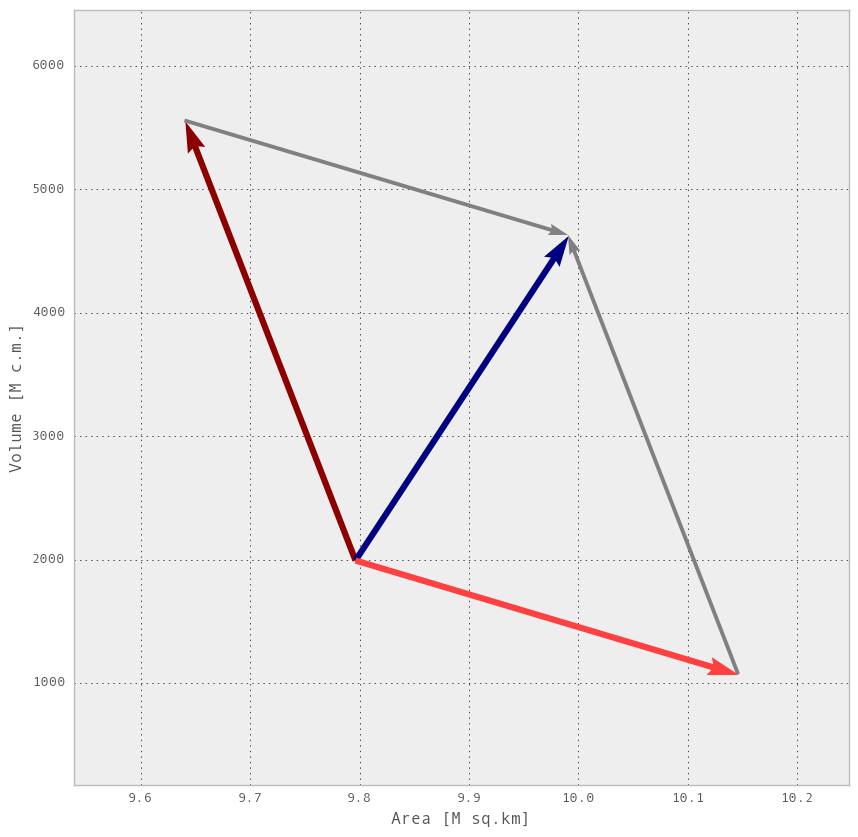

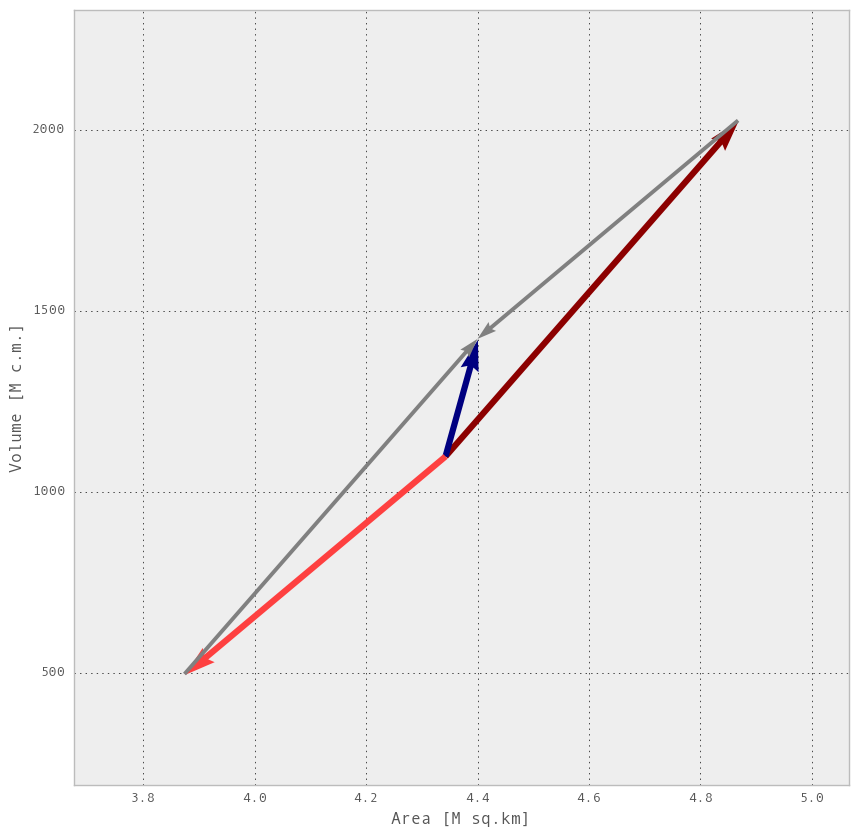

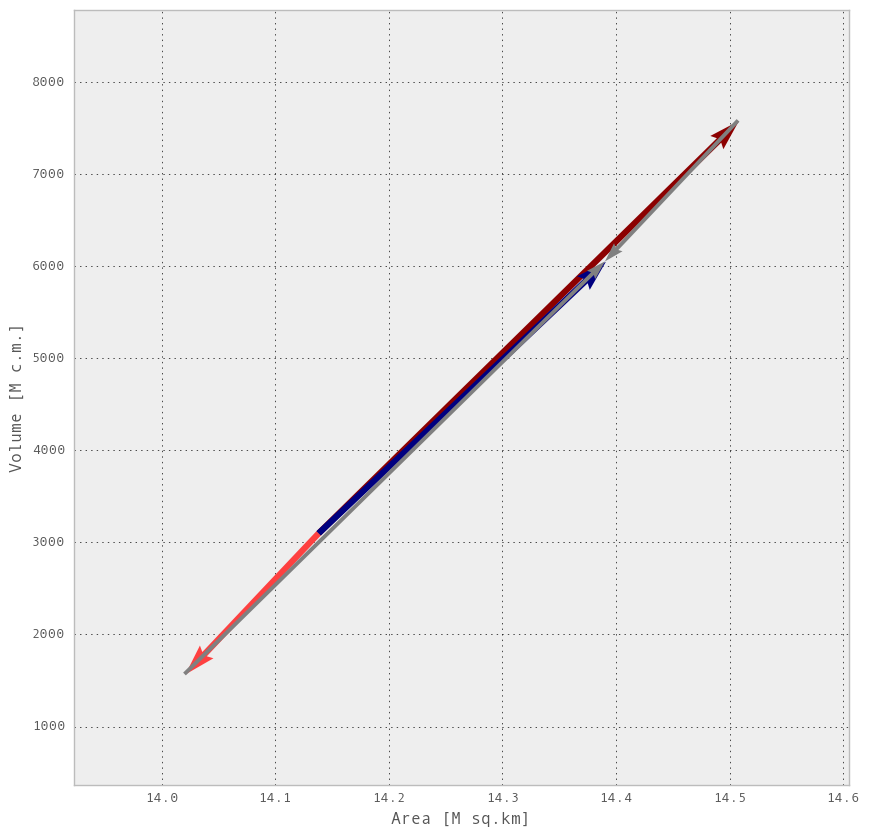

In [29]:
# Getting the values for printing the triangles
# forestDataReg:	scen 	parName 	region 	forType 	freeDim 	year 	value 	spGroup

area0 = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2015)
                     ]  # ha

#forArea_total_a1b = forArea_total[forArea_total['scen'].isin(scenarios_a1b)]

vol0  = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2015)
                     ] # already in M m^3
area0_t =  area0.value.sum() / 1000000
vol0_t  =  vol0.value.sum()
area0_b =  area0[area0['spGroup']=='Broadleaved'].value.sum() / 1000000
area0_c =  area0[area0['spGroup']=='Coniferous'].value.sum()  / 1000000
vol0_b  =  vol0[vol0['spGroup']  =='Broadleaved'].value.sum()
vol0_c  =  vol0[vol0['spGroup']  =='Coniferous'].value.sum()

# scenario arpege_a1b, 2100
areat = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
volt  = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
areat_t =  areat.value.sum() / 1000000
volt_t  =  volt.value.sum()
areat_b =  areat[areat['spGroup']=='Broadleaved'].value.sum() / 1000000
areat_c =  areat[areat['spGroup']=='Coniferous'].value.sum()  / 1000000
volt_b  =  volt[volt['spGroup']  =='Broadleaved'].value.sum()
volt_c  =  volt[volt['spGroup']  =='Coniferous'].value.sum()

# scenario constant, 2100
areac = forestDataReg[(forestDataReg['scen']=='constant') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
volc  = forestDataReg[(forestDataReg['scen']=='constant') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
areac_t =  areac.value.sum() / 1000000
volc_t  =  volc.value.sum()
areac_b =  areac[areac['spGroup']=='Broadleaved'].value.sum() / 1000000
areac_c =  areac[areac['spGroup']=='Coniferous'].value.sum()  / 1000000
volc_b  =  volc[volc['spGroup']  =='Broadleaved'].value.sum()
volc_c  =  volc[volc['spGroup']  =='Coniferous'].value.sum()

# scenario arpege_a1b_nomgm, 2100
arean = forestDataReg[(forestDataReg['scen']=='arpege_a1b_nomgm') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
voln  = forestDataReg[(forestDataReg['scen']=='arpege_a1b_nomgm') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
arean_t =  arean.value.sum() / 1000000
voln_t  =  voln.value.sum()
arean_b =  arean[arean['spGroup']=='Broadleaved'].value.sum() / 1000000
arean_c =  arean[arean['spGroup']=='Coniferous'].value.sum()  / 1000000
voln_b  =  voln[voln['spGroup']  =='Broadleaved'].value.sum()
voln_c  =  voln[voln['spGroup']  =='Coniferous'].value.sum()


print("Starting points (broad/con/tot):")
print(area0_b)
print(area0_c)
print(area0_t)
print(vol0_b)
print(vol0_c)
print(vol0_t)

print("End of the total cc vector (broad/con/tot):")
print(areat_b)
print(areat_c)
print(areat_t)
print(volt_b)
print(volt_c)
print(volt_t)

print("End of the nocc vector (broad/con/tot):")
print(areac_b)
print(areac_c)
print(areac_t)
print(volc_b)
print(volc_c)
print(volc_t)

print("End of the nomgm vector (broad/con/tot):")
print(arean_b)
print(arean_c)
print(arean_t)
print(voln_b)
print(voln_c)
print(voln_t)


print("Area/vol 2015->2100 (three diagrams for br/con/total) comparition between total cc effect (scenario arpege_a1b, black), constant dynamics (including managemnt, red) and, by diff, cc effect alone (green)")
# Broadleaved triangle..
# plotVectorChart_inner(origin,end1,endt,xlabel,ylabel,filename)
parserlib.plotVectorChart_inner((area0_b,vol0_b),(areac_b,volc_b),(areat_b,volt_b),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_cc_b.png", comp1_color='#8c0000', totcomp_color='#000080', diffcomp_color='#fe4040')
parserlib.plotVectorChart_inner((area0_c,vol0_c),(areac_c,volc_c),(areat_c,volt_c),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_cc_c.png", comp1_color='#8c0000', totcomp_color='#000080', diffcomp_color='#fe4040')
parserlib.plotVectorChart_inner((area0_t,vol0_t),(areac_t,volc_t),(areat_t,volt_t),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_cc_t.png", comp1_color='#8c0000', totcomp_color='#000080', diffcomp_color='#fe4040')



Area/vol 2015->2100 (three diagrams for br/con/total) comparition between total cc effect (scenario arpege_a1b, black), cc effect without management (red) and, by diff, management effect alone (green)


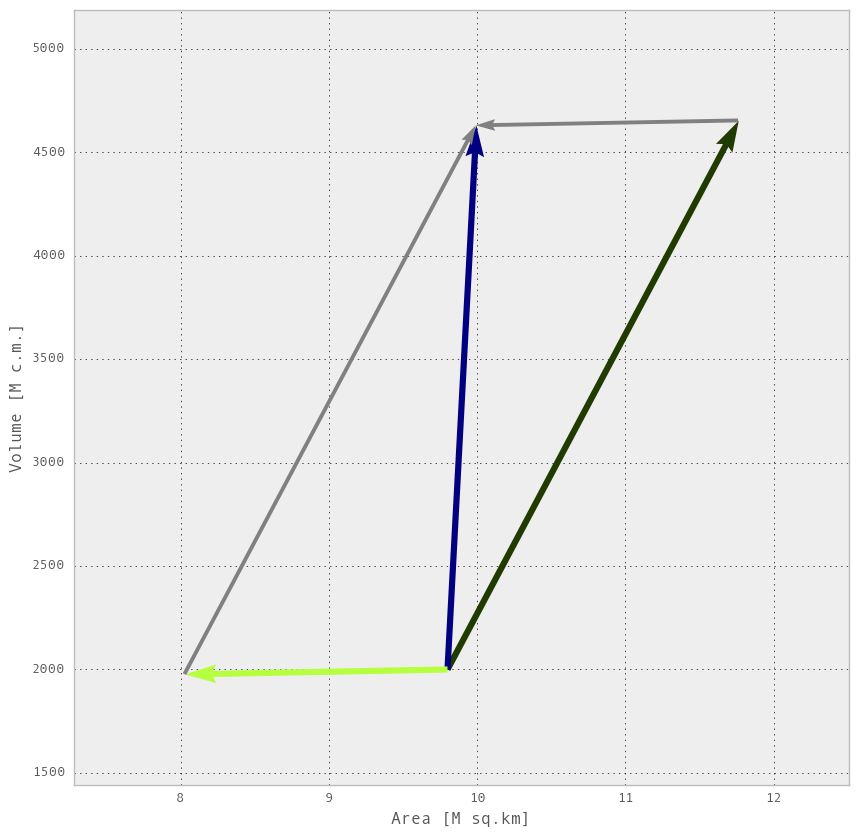

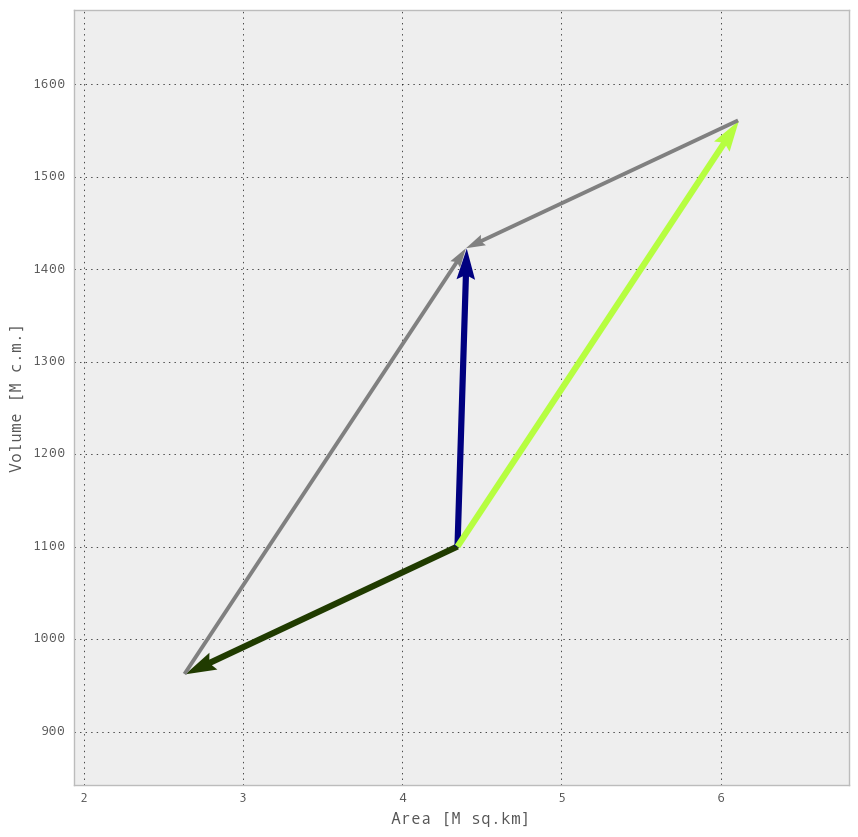

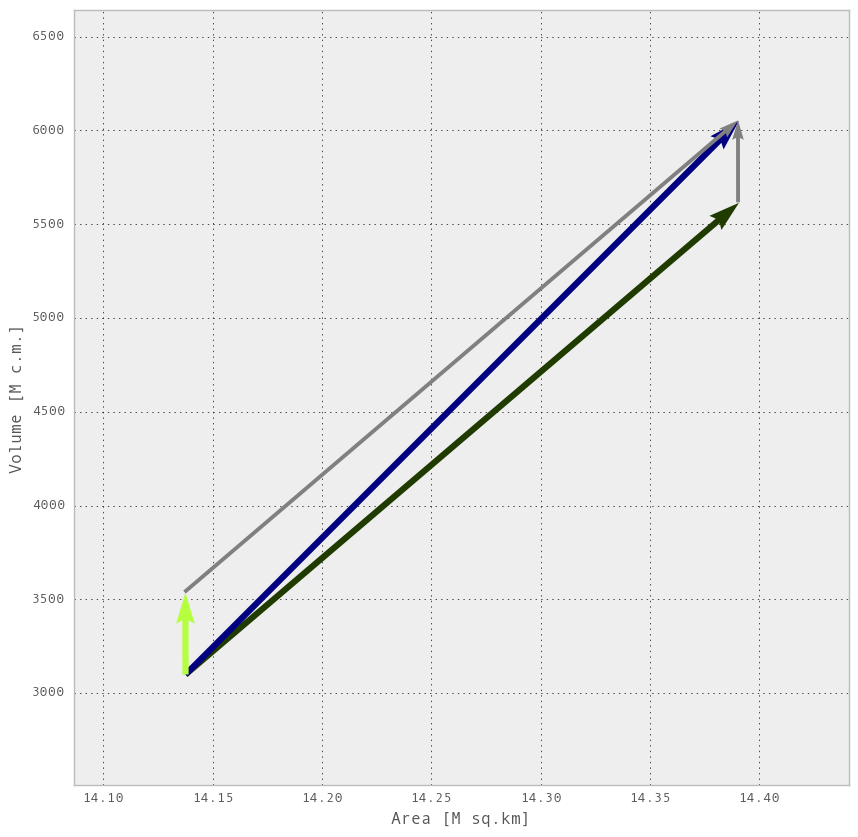

In [30]:
print("Area/vol 2015->2100 (three diagrams for br/con/total) comparition between total cc effect (scenario arpege_a1b, black), cc effect without management (red) and, by diff, management effect alone (green)")
parserlib.plotVectorChart_inner((area0_b,vol0_b),(arean_b,voln_b),(areat_b,volt_b),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_mgm_b.png", comp1_color='#203b00', totcomp_color='#000080', diffcomp_color='#b6fe40')
parserlib.plotVectorChart_inner((area0_c,vol0_c),(arean_c,voln_c),(areat_c,volt_c),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_mgm_c.png", comp1_color='#203b00', totcomp_color='#000080', diffcomp_color='#b6fe40')
parserlib.plotVectorChart_inner((area0_t,vol0_t),(arean_t,voln_t),(areat_t,volt_t),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vectors_mgm_t.png", comp1_color='#203b00', totcomp_color='#000080', diffcomp_color='#b6fe40')